# N154 — Is delayed advantage over fixed replay available and predictable?

Authorized 5 November 2026. N151–N153 learned useful chosen-action H1 signals but
did not beat sustained quarter-rate replay. Smaller rates reduced total LR dose;
RankMe rewards sometimes compensated for predicted reconstruction damage. Before
deploying a more complex MPC, measure matched-dose multi-step alternatives and
qualify prediction of their paired advantage over replay.

This notebook is a paired identification and predictor-qualification experiment.
It does not deploy MPC or automatically launch a controller after qualification.

## Four eight-update templates

0. Replay: eight quarter-rate replay updates.
1. Caution/boost: two 1/8-rate replay, two 3/8-rate replay, four quarter-rate replay.
2. Boost/caution: two 3/8-rate replay, two 1/8-rate replay, four quarter-rate replay.
3. Current/replay: two quarter-rate current-five, six quarter-rate replay updates.

Rates are multipliers of the original nominal LR=1e-4. Every update processes five
gradient images with one Adam step and clipping at 1. Replay uses .5 first current
view plus .5 mean of four past images; current-five uses four additional views of
the current image instead. In each eight-update block: eight optimizer steps,
40 gradient images, nominal-LR sum 2. No candidate has a smaller total LR budget.
Adam moments/decay remain unchanged; matched LR sum does not equal identical
parameter displacement. The larger .375 rate is a new diagnostic candidate.

Enumerate all four-by-four first/second-block combinations: 16 plans of horizon
16, each with 16 steps, 80 gradient images and LR sum 4. Always-replay is plan 00.
Measure H8 for the four unique first blocks and H16 for all 16 plans. Share the
exact captured H8 state across its four second-block branches to avoid duplicated
training work. Scientific branch execution is 160 steps per origin, not 256.

## States, data and causal information

Reuse N152's three ordered 40-clip development streams and original parent. The
previous experiments already informed this design; these are not fresh test data.
The remaining ten unused clips stay unused. Reconstruct each N152 fixed-replay
trajectory exactly, using its stored training/replay/assay seeds and audit exclusions.
Verify sampled incoming pre-loss readings and final full learner fingerprints.

Select 32 origins per stream, one per distinct clip drawn without replacement from
clip indices 4..38. Use seeds 154101/154201/154301 and an offset in [16,48] within
each selected clip. Freeze all 96 origins before training. Each 16-update plan and
its following 16-image diagnostic audit remain inside that clip and before index
3776. No selection based on health, outcomes or known scene labels.

At an origin restore the same full neural network, Adam, mode and CPU/CUDA RNG state
for every plan. Each relative arrival uses the same original N152 training seed and
causal replay identities across plans. Replay may use earlier arrivals within its
own branch, never future images. Verify identical first/second training RNG draws
across all plans. Every completed case restores the original parent; the continuing
reference prefix follows fixed replay regardless of any diagnostic result.

Prediction inputs are restricted to the origin: N152's 17 context features, log1p
Adam first/second moment L2 norms, and bank-loss quantiles .1/.5/.9 (22 features).
The current arriving image is available; subsequent images are unknown at planning
time. Previous health changes come only from the preceding executed reference step.
No clip ID, time, future image statistics, plan outcomes or diagnostic-audit metrics
enter the predictor. Family/origin IDs are grouping and audit metadata only.

The runtime plans are open-loop template schedules conditional on future arriving
images, not a claim to know those images. We observe their realized outcomes here
retrospectively to train direct multi-step advantage predictors. A later receding-
horizon controller would execute a whole first eight-update block before replanning,
so LR compensation cannot be abandoned mid-block. N154 does not simulate that
closed-loop policy or assume its long-run performance from these forks.

## Paired outcomes and health

At each origin freeze the current 256-image FIFO bank and its identity-specific
reconstruction masks for the whole 16-update comparison. It excludes reserved
initial-audit images, but overlaps past replay content and is not a generalization
audit. Measure freshly computed bank loss and raw-spectrum RankMe before, at H8
and at H16. Membership replacement never enters the plan target.

Record actual reconstruction of each incoming image before and after its update,
plus embedding norm and pre/post cosine. The planning objective is mean incoming
PRE-update reconstruction over the horizon. The first image is already known and
its pre-loss is common across plans; subsequent images provide delayed outcomes.

For every plan, paired advantages over always-replay are:
1. Replay mean incoming pre-loss minus plan mean incoming pre-loss.
2. Replay terminal frozen-bank loss minus plan terminal bank loss.
3. Plan terminal frozen-bank RankMe minus replay terminal bank RankMe.

Positive values always favor the candidate. Normalize these three targets by the
origin current loss, bank loss and bank RankMe respectively. These denominators
are available at decision time. No additive rank reward is used. Also evaluate
the reserved 64-image initial audit and images i+16..i+31 after the H16 endpoint;
these diagnostic populations never influence predictions, selection or margins.
The original N152 final future tail at 3776..3839 remains unused by this experiment.

## Prediction and grouped evaluation

Fit separate ridge heads per candidate plan to the three paired advantage outputs.
Use direct H8 and H16 predictors; do not recursively propagate H1 with an invented
constant future image context. Always-replay advantage is structurally zero.
Fixed ridge alpha=10, intercept penalty=1. Train-only feature centering/scaling,
scale floor 1e-4, standardized inputs clipped to [-5,5]. No hyperparameter sweep.

Outer evaluation leaves one entire stream out, training on the other two. All plans
and nearby origins from a stream stay together; this is stronger grouping than
splitting individual branches or overlapping banks. There are three outer folds.
Within each outer training set, fit on one training stream and predict the other,
then reverse. Use those inner held-out residuals to set per-plan/output one-sided
90th-percentile overprediction margins, floored at zero. No outer test target can
affect scales, weights, calibration, choice or the training-selected constant plan.

Compare these selection rules on the outer held-out origins:
- Always replay.
- Best constant plan selected using only mean training advantages, with nonnegative
  mean training bank-loss and rank advantages; otherwise replay.
- Raw predictor: positive predicted incoming advantage with nonnegative predicted
  bank-loss and rank advantages; choose the largest incoming advantage.
- Calibrated predictor: apply the same conditions to prediction minus its inner-
  calibration margin, with replay fallback. This is an empirical heuristic, not
  guaranteed joint coverage or guaranteed health protection.
- Measured guarded oracle: same rule using actual outcomes; diagnostic upper bound.
- Measured unconstrained oracle: maximize actual incoming advantage, allowing
  retention damage; distinguishes action opportunity from constraint compatibility.
- Uniform random plan: report its expected measured advantage over all 16 plans.

Report realized raw/relative advantages, harmful switches, retention violations,
top-choice agreement, regret to measured unconstrained oracle, paired-advantage RMSE
versus zero-advantage prediction, per-plan outcomes and per-stream results. Also
take the H8 guarded oracle's first block and append replay, showing whether its
benefit survives at H16. Do not infer significance from treating origins/frames as
independent replicates; streams share one parent and have correlated histories.

Qualification is descriptive, with no automatic deployment: first ask whether
guard-compatible oracle gains exist consistently; then whether held-out selection
realizes positive advantage, controls damage and improves on the training-selected
constant plan. If only the oracle wins, work on prediction. If no useful oracle
advantage exists, revisit the plan library. If the calibrated rule never switches,
report lack of qualified evidence rather than calling it a successful MPC.

This is offline identification. Fitting an advantage head from paired trials does
not imply an online chosen-only learner observes unexecuted baseline outcomes.
A subsequent deployment must specify valid delayed feedback or separately charged
paired audits; N154 makes no online-learning claim for this qualification model.

## Reliability, work and live notebook

Unit tests verify exact block/plan budgets, safe grouped origins, retention guards
and test-target exclusion from fitting/calibration/selection. GPU preflight runs
all 16 plans, interrupts collection after five cases and resumes. Require exact
case equality, parent restoration, paired RNG, exact prefix state and matching
optimizer counts. Older source/results remain frozen.

Canonical scientific work: 96 origins x 160 unique branch updates = 15,360 steps /
76,800 gradient images; three reference prefixes add 10,368 steps / 51,840 gradient
images. Recovered partial prefixes may add repeated work; these counts describe
unique intended execution, not all engineering/retry work. Each logical H16 plan
still represents 16 steps/80 images even though its first block is shared.

Save complete origin cases atomically with payload hashes and retain two full
prefix checkpoints. Resume partial origins without losing completed cases. Respect
stop-request.json and a 1 GiB disk reserve. Freeze source/input/plan/preflight hashes
before scientific collection. Notebook 154 starts with this protocol and updates
actual incoming/bank health and plan effects; held-out qualification waits until all
96 origins and exact-prefix checks finish. Live report uses localhost:8854.


# N154 — Paired multi-step MPC identification

Status: **complete**. 1536/1536 plan outcomes; 96/96 complete origins.

Active: engineering; origin —; prefix —.

This is an offline diagnostic on reused development streams. No MPC policy is deployed. Positive advantages favor a plan over always-replay. Every plan has equal optimizer steps, gradient images and LR sum.

## Horizon 8

stream_a: 32/32 origins; measured guarded oracle switches 14; unconstrained switches 31.

stream_b: 32/32 origins; measured guarded oracle switches 7; unconstrained switches 32.

stream_c: 32/32 origins; measured guarded oracle switches 10; unconstrained switches 32.

| Selection rule | Incoming loss advantage | Frozen-bank loss advantage | Frozen-bank RankMe advantage | Switches / 96 |
|---|---:|---:|---:|---:|
| baseline | +0.0000000 | +0.0000000 | +0.0000000 | 0 |
| constant | +0.0000827 | -0.0000001 | -0.0001631 | 32 |
| raw | +0.0000689 | +0.0000156 | +0.0010212 | 27 |
| calibrated | +0.0000000 | +0.0000000 | +0.0000000 | 0 |
| oracle_guarded | +0.0001919 | +0.0000976 | +0.0019243 | 31 |
| oracle_unconstrained | +0.0009043 | -0.0006848 | +0.0003581 | 95 |

Oracle rules use measured outcomes and are unattainable references. Constant plan is chosen on training streams only. Raw/calibrated predictors see no held-out outcomes during fitting or selection.

stream_a: paired-advantage RMSE [0.0009589782654296643, 0.00096423878646075, 0.004011880191983988]; zero-advantage RMSE [0.0010811134007816527, 0.0011670675071114211, 0.003918620188105193]; calibrated mean raw advantage [0.0, 0.0, 0.0].

stream_b: paired-advantage RMSE [0.0007576291206514488, 0.0008528470200787837, 0.004075952318692656]; zero-advantage RMSE [0.0008409503650376904, 0.0008930436244952572, 0.003377458973199467]; calibrated mean raw advantage [0.0, 0.0, 0.0].

stream_c: paired-advantage RMSE [0.001243560092227531, 0.0015943601447065935, 0.0026453720771383352]; zero-advantage RMSE [0.0012802432578780734, 0.002008594361337974, 0.0021528545724043883]; calibrated mean raw advantage [0.0, 0.0, 0.0].

## Horizon 16

stream_a: 32/32 origins; measured guarded oracle switches 22; unconstrained switches 32.

stream_b: 32/32 origins; measured guarded oracle switches 18; unconstrained switches 32.

stream_c: 32/32 origins; measured guarded oracle switches 21; unconstrained switches 32.

| Selection rule | Incoming loss advantage | Frozen-bank loss advantage | Frozen-bank RankMe advantage | Switches / 96 |
|---|---:|---:|---:|---:|
| baseline | +0.0000000 | +0.0000000 | +0.0000000 | 0 |
| constant | +0.0000000 | +0.0000000 | +0.0000000 | 0 |
| raw | +0.0000313 | -0.0000705 | +0.0003218 | 55 |
| calibrated | +0.0000000 | +0.0000000 | +0.0000000 | 0 |
| oracle_guarded | +0.0002862 | +0.0000847 | +0.0016724 | 61 |
| oracle_unconstrained | +0.0013603 | -0.0012013 | -0.0028400 | 96 |

Oracle rules use measured outcomes and are unattainable references. Constant plan is chosen on training streams only. Raw/calibrated predictors see no held-out outcomes during fitting or selection.

stream_a: paired-advantage RMSE [0.0009507620225916425, 0.0011644222620003834, 0.004963134188284083]; zero-advantage RMSE [0.001125788756874689, 0.0013640787243228343, 0.004557795340192044]; calibrated mean raw advantage [0.0, 0.0, 0.0].

Independent audit advantage for calibrated choice [initial loss, initial RankMe, post-plan future loss, post-plan future RankMe]: [0.0, 0.0, 0.0, 0.0]. These audits do not guide selection.

stream_b: paired-advantage RMSE [0.0008591301308355867, 0.000824056839448236, 0.00600326459723423]; zero-advantage RMSE [0.0009683049338908217, 0.0011900238992524094, 0.00592497736136038]; calibrated mean raw advantage [0.0, 0.0, 0.0].

Independent audit advantage for calibrated choice [initial loss, initial RankMe, post-plan future loss, post-plan future RankMe]: [0.0, 0.0, 0.0, 0.0]. These audits do not guide selection.

stream_c: paired-advantage RMSE [0.0013165548232238838, 0.001675885720330267, 0.003043108132333448]; zero-advantage RMSE [0.0013307480475798054, 0.001945086736918458, 0.0026012798571967703]; calibrated mean raw advantage [0.0, 0.0, 0.0].

Independent audit advantage for calibrated choice [initial loss, initial RankMe, post-plan future loss, post-plan future RankMe]: [0.0, 0.0, 0.0, 0.0]. These audits do not guide selection.

H8-oracle choices are also followed by an ordinary replay block to check whether their gains survive to H16. A separate 16-image post-plan audit and the reserved initial audit never enter predictor features, objectives or qualification margins.

No automatic controller launch follows qualification. Three held-out stream folds are development evidence, not independent external confirmation.


### Matched-dose plans: measured delayed reconstruction advantage
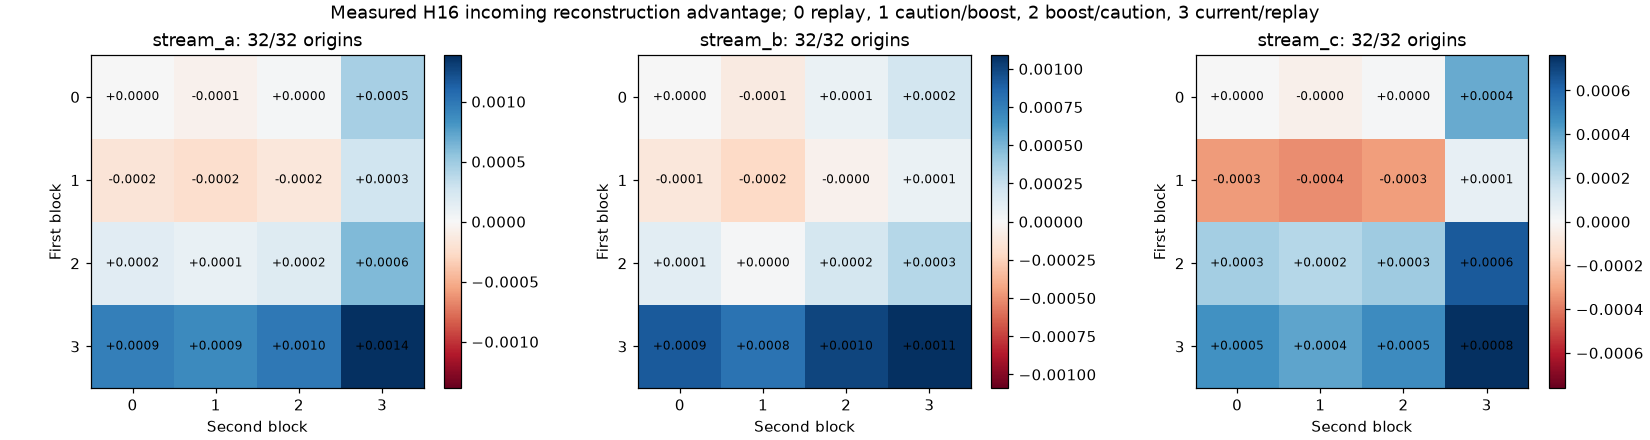

### Actual incoming-image and frozen-bank health over each plan
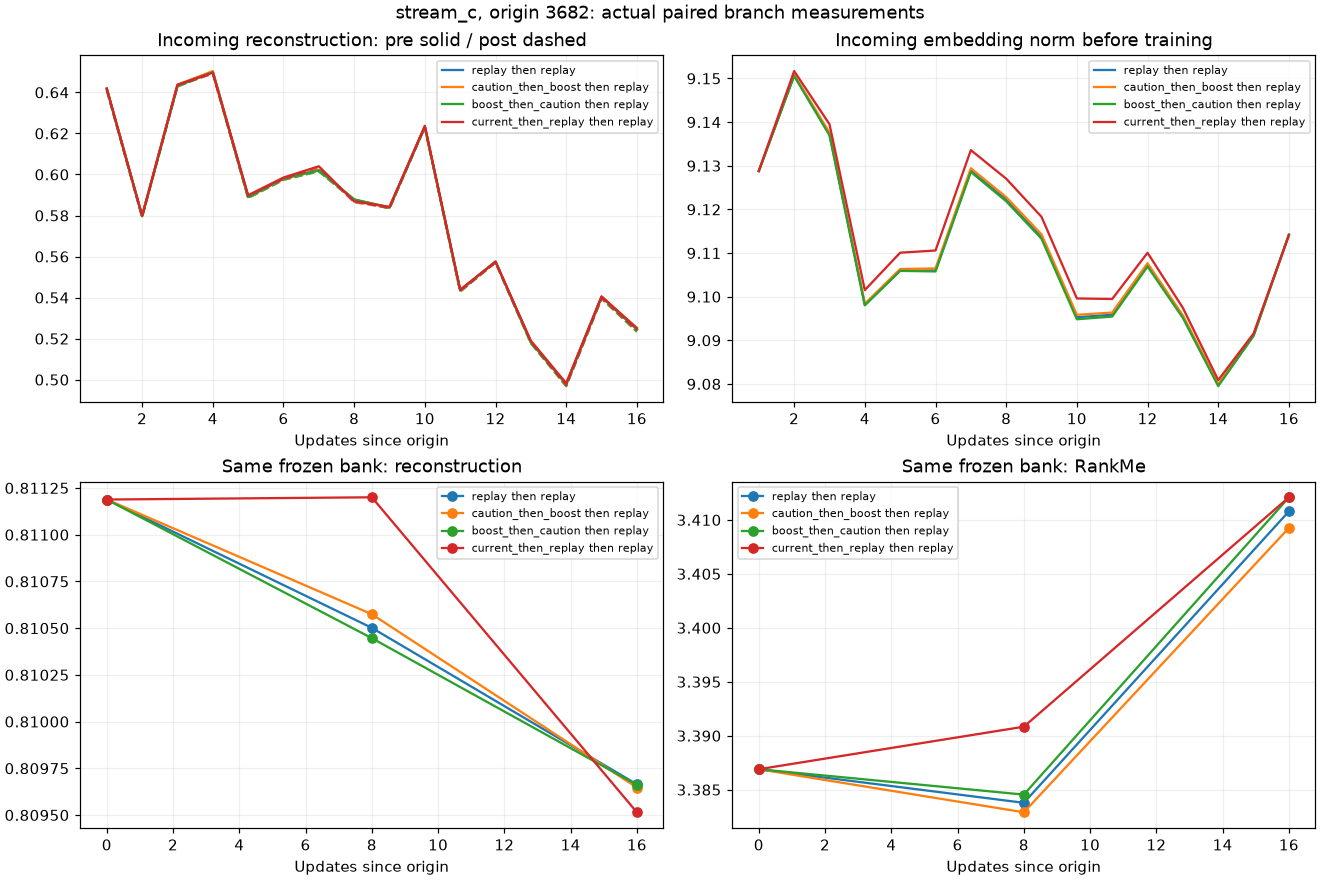

### Can the predictor realize the measured planning opportunities?
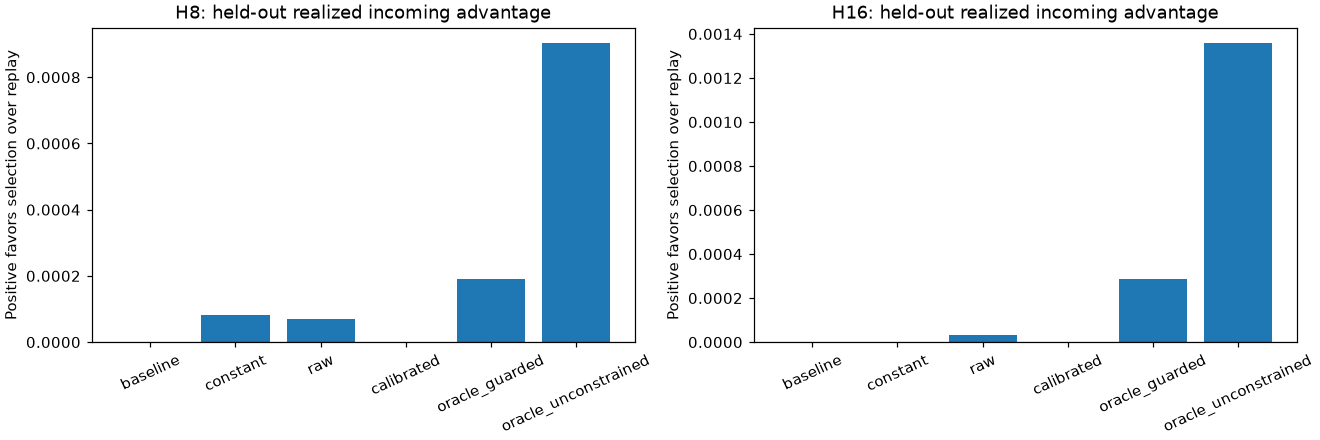